In [ ]:

import pandas as pd
import re

# 1. Periksa dataset
print("Ukuran dataset awal:", df.shape)
print("Kolom:", df.columns.tolist())

# 2. Tampilkan 15 komentar paling sering
komentar_populer = (
    df["Comment"]
    .astype("string")
    .str.strip()
    .value_counts()
)

hasil_komentar = komentar_populer.head(15).reset_index()
hasil_komentar.columns = ["Komentar", "Frekuensi"]

print("\n15 komentar paling sering:")
display(hasil_komentar)

# 3. Buat salinan untuk screening
df_screening = df.copy()

# Rapikan komentar dan tanggal
df_screening["Comment"] = (
    df_screening["Comment"]
    .astype("string")
    .str.strip()
)

df_screening["Date"] = pd.to_datetime(
    df_screening["Date"],
    errors="coerce"
)

# 4. Normalisasi komentar
def normalisasi_teks(teks):
    teks = str(teks).lower().strip()
    teks = re.sub(r"\s+", " ", teks)
    return teks

df_screening["Comment_Normalized"] = (
    df_screening["Comment"].map(normalisasi_teks)
)

# Tandai komentar yang berulang
df_screening["Duplicate_Comment"] = (
    df_screening.duplicated(
        subset=["Comment_Normalized"],
        keep="first"
    )
)

# 5. Screening kata kunci awal
keywords = [
    "ai", "face swap", "faceswap", "deepfake",
    "wajah", "muka", "foto", "video", "prompt",
    "edit", "palsu", "bahaya", "keren", "ngeri",
    "menipu"
]

pattern = r"\b(?:" + "|".join(
    re.escape(k) for k in keywords
) + r")\b"

df_screening["Keyword_Match"] = (
    df_screening["Comment_Normalized"]
    .str.contains(pattern, regex=True, na=False)
)

# 6. Ringkasan hasil screening
komentar_kosong = (
    df_screening["Comment"].isna()
    | df_screening["Comment"].eq("")
).sum()

print("\n--- RINGKASAN SCREENING ---")
print("Jumlah data awal:", len(df_screening))
print("Komentar kosong:", komentar_kosong)
print("Komentar unik:", df_screening["Comment_Normalized"].nunique())
print("Komentar berulang:", df_screening["Duplicate_Comment"].sum())
print("Komentar dengan kata kunci:", df_screening["Keyword_Match"].sum())
print("Komentar tanpa kata kunci:", (~df_screening["Keyword_Match"]).sum())

# Tinjau contoh komentar tanpa kata kunci
print("\nContoh komentar tanpa kata kunci:")
display(
    df_screening.loc[
        ~df_screening["Keyword_Match"],
        ["Comment", "Keyword_Match"]
    ].head(20)
)

# 7. Siapkan dataset analisis tanpa identitas pengguna
df_analisis = df_screening[
    [
        "Date",
        "Comment",
        "Comment_Normalized",
        "Duplicate_Comment",
        "Keyword_Match"
    ]
].copy()

df_analisis = df_analisis[
    df_analisis["Comment"].notna()
    & df_analisis["Comment"].str.strip().ne("")
].copy()

print("\nJumlah data untuk analisis:", len(df_analisis))
display(df_analisis.head())

# 8. Simpan hasil
df_screening.to_csv(
    "hasil_screening_ai_face_swap.csv",
    index=False,
    encoding="utf-8-sig"
)

df_analisis.to_csv(
    "dataset_analisis_ai_face_swap.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFile screening dan dataset analisis berhasil disiapkan.")

from google.colab import files

files.download("hasil_screening_ai_face_swap.csv")
files.download("dataset_analisis_ai_face_swap.csv")

Ukuran dataset awal: (1000, 6)
Kolom: ['Name', 'Username', 'Profile ID', 'Date', 'Comment', '(view source)']

15 komentar paling sering:


,Komentar,Frekuensi
0,Prompt,91
1,Asli,41
2,"Halo kak, udah dikirim ke DM ya! 🤩🔥",10
3,asli,10
4,"cek DMnya ya, kak! 📬",9
5,Amin,9
6,"Udah gua kirim ke DM ya, boss! 🤩🔥",7
7,amin,6
8,Promt,6
9,ASLI,6



--- RINGKASAN SCREENING ---
Jumlah data awal: 1000
Komentar kosong: 0
Komentar unik: 772
Komentar berulang: 228
Komentar dengan kata kunci: 240
Komentar tanpa kata kunci: 760

Contoh komentar tanpa kata kunci:


,Comment,Keyword_Match
1,@hai.shilaa...ikuti berita yg akun asli,False
3,Setujuu👏👏👏,False
4,@desiriskaa_ iyaa lagi😢😭,False
5,@ayuksrik Mulu bgt bang. Kalah film buatan ind...,False
6,@vdy.cha *mulus,False
7,@dfi.rrd4 benerr,False
10,Namanya pit nah akhir zaman Jare pak ustadz,False
12,@adityaaziss iya lagi😂,False
13,😢,False
14,Terima kasih infonya ❤️,False



Jumlah data untuk analisis: 1000


,Date,Comment,Comment_Normalized,Duplicate_Comment,Keyword_Match
0,2026-03-04 14:22:28,"Bahaya, enak jaman dulu","bahaya, enak jaman dulu",False,True
1,2026-03-04 14:49:07,@hai.shilaa...ikuti berita yg akun asli,@hai.shilaa...ikuti berita yg akun asli,False,False
2,2026-03-04 14:56:09,Ini sebenernya ngeri apa keren?,ini sebenernya ngeri apa keren?,False,True
3,2026-03-04 16:15:59,Setujuu👏👏👏,setujuu👏👏👏,False,False
4,2026-03-05 05:02:48,@desiriskaa_ iyaa lagi😢😭,@desiriskaa_ iyaa lagi😢😭,False,False



File screening dan dataset analisis berhasil disiapkan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Ambil sampel komentar yang belum cocok dengan kata kunci
sampel_screening = df_screening.loc[
    ~df_screening["Keyword_Match"],
    ["Comment"]
].sample(
    n=min(100, (~df_screening["Keyword_Match"]).sum()),
    random_state=42
).copy()

# Tambahkan kolom label untuk pemeriksaan manual
sampel_screening["Relevansi"] = ""

display(sampel_screening)

# Simpan agar bisa diperiksa di Excel
sampel_screening.to_csv(
    "sampel_screening_manual.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files
files.download("sampel_screening_manual.csv")

,Comment,Relevansi
484,@_mlnsdyh iya mana emak gua suka bgt percya be...,
398,lh bukannya lu yg ngarang? ksih sumber/jurnal ...,
140,Ini kerenn,
614,😭😭😭🤣🤣,
153,Bang ke israel pasti 1000% jadi PM,
...,...,...
101,emang sengaja kalih tanda kiamatkhn banyaknya ...,
873,Asli,
430,yg pertama negeri kali😢,
893,Asli,


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)

print("Ukuran dataset:", df.shape)
display(df.head())

Saving dataset_analisis_ai_face_swap.csv to dataset_analisis_ai_face_swap (2).csv
Ukuran dataset: (1000, 5)


,Date,Comment,Comment_Normalized,Duplicate_Comment,Keyword_Match
0,2026-03-04 14:22:28,"Bahaya, enak jaman dulu","bahaya, enak jaman dulu",False,True
1,2026-03-04 14:49:07,@hai.shilaa...ikuti berita yg akun asli,@hai.shilaa...ikuti berita yg akun asli,False,False
2,2026-03-04 14:56:09,Ini sebenernya ngeri apa keren?,ini sebenernya ngeri apa keren?,False,True
3,2026-03-04 16:15:59,Setujuu👏👏👏,setujuu👏👏👏,False,False
4,2026-03-05 05:02:48,@desiriskaa_ iyaa lagi😢😭,@desiriskaa_ iyaa lagi😢😭,False,False


In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)

print("Ukuran dataset:", df.shape)
display(df.head())

Saving sampel_screening_manual.csv to sampel_screening_manual (2).csv
Ukuran dataset: (100, 2)


,Comment,Relevansi
0,@_mlnsdyh iya mana emak gua suka bgt percya be...,NaN
1,lh bukannya lu yg ngarang? ksih sumber/jurnal ...,NaN
2,Ini kerenn,NaN
3,😭😭😭🤣🤣,NaN
4,Bang ke israel pasti 1000% jadi PM,NaN


In [ ]:
# Langkah 2: Ambil sampel acak untuk pelabelan manual

df_manual = df[["Comment"]].copy()

df_manual["Comment"] = (
    df_manual["Comment"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df_manual = df_manual[df_manual["Comment"] != ""]

sampel_manual = df_manual.sample(
    n=min(100, len(df_manual)),
    random_state=42
).copy()

sampel_manual["Relevansi"] = ""
sampel_manual["Sentimen_Manual"] = ""

display(sampel_manual.head(10))

sampel_manual.to_csv(
    "sampel_sentimen_manual.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Jumlah sampel:", len(sampel_manual))

,Comment,Relevansi,Sentimen_Manual
83,asli,,
53,"Udah gua kirim ke DM ya, boss! 🤩🔥",,
70,Apa kabar yesus cabuli Maria umur 3 tahun ??,,
45,Gimana cara bikin hidungnya😢kok bisa beda gitu🗿,,
44,Asli,,
39,spill caranya,,
22,Bg coba jadi Donal trum,,
80,🙌,,
10,.,,
0,@_mlnsdyh iya mana emak gua suka bgt percya be...,,


Jumlah sampel: 100


In [ ]:
from google.colab import files
files.download("sampel_sentimen_manual.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
nama_file_manual = next(iter(uploaded))

label_manual = pd.read_csv(nama_file_manual)

print("Jumlah sampel:", len(label_manual))
print("Kolom:", label_manual.columns.tolist())
display(label_manual.head())

Saving sampel_sentimen_manual (1).csv to sampel_sentimen_manual (1).csv
Jumlah sampel: 100
Kolom: ['Comment', 'Relevansi', 'Sentimen_Manual']


,Comment,Relevansi,Sentimen_Manual
0,asli,NaN,NaN
1,"Udah gua kirim ke DM ya, boss! 🤩🔥",NaN,NaN
2,Apa kabar yesus cabuli Maria umur 3 tahun ??,NaN,NaN
3,Gimana cara bikin hidungnya😢kok bisa beda gitu🗿,NaN,NaN
4,Asli,NaN,NaN


In [ ]:
# Periksa label yang tersedia
print("Label relevansi:")
print(label_manual["Relevansi"].value_counts(dropna=False))

print("\nLabel sentimen:")
print(label_manual["Sentimen_Manual"].value_counts(dropna=False))

Label relevansi:
Relevansi
NaN    100
Name: count, dtype: int64

Label sentimen:
Sentimen_Manual
NaN    100
Name: count, dtype: int64


In [ ]:
!pip -q install transformers torch sentencepiece

In [ ]:
import pandas as pd
import torch
from transformers import pipeline

print("GPU tersedia:", torch.cuda.is_available())

GPU tersedia: False


In [ ]:
# Langkah 4B: Muat model sentimen bahasa Indonesia

from transformers import pipeline
import torch

nama_model = "Aardiiiiy/indobertweet-base-Indonesian-sentiment-analysis"

device = 0 if torch.cuda.is_available() else -1

analisis_sentimen = pipeline(
    "text-classification",
    model=nama_model,
    device=device
)

print("Model berhasil dimuat.")
print("Label model:", analisis_sentimen.model.config.id2label)

config.json:   0%|          | 0.00/994 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  442MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/235k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

Model berhasil dimuat.
Label model: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


In [ ]:
# Langkah 5: Bersihkan teks dan jalankan prediksi

import pandas as pd

df_hasil = df.copy()

df_hasil["Comment"] = (
    df_hasil["Comment"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Hanya proses komentar yang tidak kosong
mask_isi = df_hasil["Comment"] != ""

teks = df_hasil.loc[mask_isi, "Comment"].tolist()

prediksi = analisis_sentimen(
    teks,
    batch_size=16,
    truncation=True
)

df_hasil["Sentimen_Otomatis"] = pd.NA
df_hasil["Skor_Keyakinan"] = pd.NA

for idx, hasil in zip(df_hasil.index[mask_isi], prediksi):
    label = hasil["label"].upper()

    if "POSITIVE" in label or label == "LABEL_2":
        sentimen = "Positif"
    elif "NEGATIVE" in label or label == "LABEL_0":
        sentimen = "Negatif"
    elif "NEUTRAL" in label or label == "LABEL_1":
        sentimen = "Netral"
    else:
        sentimen = "Periksa Label"

    df_hasil.loc[idx, "Sentimen_Otomatis"] = sentimen
    df_hasil.loc[idx, "Skor_Keyakinan"] = hasil["score"]

print("Prediksi selesai.")
display(
    df_hasil[
        ["Comment", "Sentimen_Otomatis", "Skor_Keyakinan"]
    ].head(20)
)

Prediksi selesai.


,Comment,Sentimen_Otomatis,Skor_Keyakinan
0,@_mlnsdyh iya mana emak gua suka bgt percya be...,Negatif,0.99558
1,lh bukannya lu yg ngarang? ksih sumber/jurnal ...,Netral,0.917067
2,Ini kerenn,Positif,0.997062
3,😭😭😭🤣🤣,Netral,0.917809
4,Bang ke israel pasti 1000% jadi PM,Negatif,0.877799
5,STRESSSS😭,Netral,0.917809
6,amin,Positif,0.940828
7,Asli,Negatif,0.995756
8,Asli,Negatif,0.995756
9,Ptomt,Netral,0.838384


In [ ]:
# Langkah 6: Hitung jumlah dan persentase sentimen

jumlah_sentimen = (
    df_hasil["Sentimen_Otomatis"]
    .value_counts()
    .reindex(["Positif", "Negatif", "Netral"], fill_value=0)
)

ringkasan = pd.DataFrame({
    "Jumlah": jumlah_sentimen,
    "Persentase (%)": (
        jumlah_sentimen / jumlah_sentimen.sum() * 100
    ).round(2)
})

display(ringkasan)

,Jumlah,Persentase (%)
Sentimen_Otomatis,,
Positif,8,8.0
Negatif,44,44.0
Netral,48,48.0


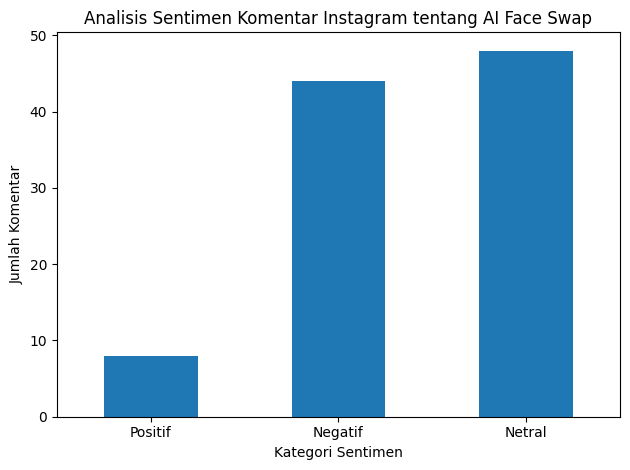

In [ ]:
import matplotlib.pyplot as plt

ringkasan["Jumlah"].plot(
    kind="bar",
    rot=0
)

plt.title("Analisis Sentimen Komentar Instagram tentang AI Face Swap")
plt.xlabel("Kategori Sentimen")
plt.ylabel("Jumlah Komentar")
plt.tight_layout()
plt.show()

In [ ]:
df_hasil.to_csv(
    "hasil_analisis_sentimen_ai_face_swap.csv",
    index=False,
    encoding="utf-8-sig"
)

from google.colab import files
files.download("hasil_analisis_sentimen_ai_face_swap.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Jumlah baris dataset asli:", len(df))
print("Jumlah baris hasil analisis:", len(df_hasil))

print("\nDistribusi sentimen:")
print(df_hasil["Sentimen_Otomatis"].value_counts(dropna=False))

print("\nContoh hasil prediksi:")
display(
    df_hasil[
        ["Comment", "Sentimen_Otomatis", "Skor_Keyakinan"]
    ].head(10)
)


Jumlah baris dataset asli: 100
Jumlah baris hasil analisis: 100

Distribusi sentimen:
Sentimen_Otomatis
Netral     48
Negatif    44
Positif     8
Name: count, dtype: int64

Contoh hasil prediksi:


,Comment,Sentimen_Otomatis,Skor_Keyakinan
0,@_mlnsdyh iya mana emak gua suka bgt percya be...,Negatif,0.99558
1,lh bukannya lu yg ngarang? ksih sumber/jurnal ...,Netral,0.917067
2,Ini kerenn,Positif,0.997062
3,😭😭😭🤣🤣,Netral,0.917809
4,Bang ke israel pasti 1000% jadi PM,Negatif,0.877799
5,STRESSSS😭,Netral,0.917809
6,amin,Positif,0.940828
7,Asli,Negatif,0.995756
8,Asli,Negatif,0.995756
9,Ptomt,Netral,0.838384
